# Zameen.com Property Models

In this notebook I clean the zameen.com data and train simple models.

- **Regression** predicts the price.
- **Classification** says if a price is expensive (1) or not (0).

Every code cell does only one small thing.

## Step 1: Import the basic tools

First I import the basic tools. `os` builds the file path, and `pandas`, `numpy` and `matplotlib` work with tables, numbers and charts.

In [4]:
# import the tools for files, tables, numbers and charts
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
# show a message so we know it worked
print('Basic tools imported')

Basic tools imported


## Step 2: Import the data tools and the scores

Now I import `train_test_split`, `StandardScaler`, `PolynomialFeatures` and the three scores I will print later.

In [5]:
# tools to split the data, scale it and make polynomial columns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
# the scores we print later
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score
print('Data tools and scores are ready')

Data tools and scores are ready


## Step 3: Import the regression models

Here I import the five models that predict the price. They all come from scikit-learn.

In [6]:
# the five regression models
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
print('Regression models are ready')

Regression models are ready


## Step 4: Import the classification models

Now I import the four models that decide if a property is expensive or not.

In [7]:
# the four classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
print('Classification models are ready')

Classification models are ready


## Step 5: Load the data file

The file is inside the Dataset folder and its name is `zameenData (1).csv`. I use `os.path.join` so the space and brackets work fine.

In [8]:
# build the path to the CSV inside the Dataset folder
data_path = os.path.join('Dataset', 'zameenData (1).csv')
# read the file into a pandas table called df
df = pd.read_csv(data_path)
# show how many rows and columns we loaded
print('Data loaded. Rows and columns:', df.shape)

Data loaded. Rows and columns: (20571, 11)


## Step 6: Look at the first rows

`df.head()` shows the first five rows, so we can see the column names and the messy text values.

In [9]:
# show the first five rows of the table
df.head()

,Unnamed: 0,agent,name,land_type,price,location,baths,area,pupose,bed,added_days
0,0,M A Associates,Muhammad Arshad,House,PKR25 Crore,"Garden Town, Lahore, Punjab",6,2 Kanal,For Sale,7,2 weeks ago
1,1,M A Associates,Muhammad Arshad,Commercial Plot,PKR60 Crore,"Gulberg, Lahore, Punjab",-,2 Kanal,For Sale,-,2 weeks ago
2,2,M A Associates,Muhammad Arshad,House,PKR15 Crore,"Gulberg, Lahore, Punjab",6,1 Kanal,For Sale,5,2 weeks ago
3,3,M A Associates,Muhammad Arshad,Commercial Plot,PKR25.5 Crore,"Wahdat Road, Lahore, Punjab",-,5.4 Kanal,For Sale,-,3 days ago
4,4,M A Associates,Muhammad Arshad,Residential Plot,PKR7.25 Crore,"Garden Town, Lahore, Punjab",-,1 Kanal,For Sale,-,2 weeks ago


## Step 7: Check the size and the types

`df.shape` tells us how many rows and columns we have. `df.info()` shows the column names and their data types.

In [10]:
# how many rows and columns do we have
print('Shape:', df.shape)
# show the column names and the data types
df.info()

Shape: (20571, 11)
<class 'pandas.DataFrame'>
RangeIndex: 20571 entries, 0 to 20570
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  20571 non-null  int64
 1   agent       16521 non-null  str  
 2   name        16507 non-null  str  
 3   land_type   20558 non-null  str  
 4   price       20558 non-null  str  
 5   location    20558 non-null  str  
 6   baths       20558 non-null  str  
 7   area        20558 non-null  str  
 8   pupose      20558 non-null  str  
 9   bed         20558 non-null  str  
 10  added_days  20558 non-null  str  
dtypes: int64(1), str(10)
memory usage: 1.7 MB


## Step 8: Drop the empty rows

Some rows are completely empty. I remove them so they cannot break the models.

In [11]:
# remove rows that are fully empty
df = df.dropna(how='all')
# show the new shape
print('Shape after dropping empty rows:', df.shape)

Shape after dropping empty rows: (20571, 11)


## Step 9: Drop the useless columns

I drop `Unnamed: 0`, `agent`, `name` and `added_days`. These columns do not help to predict the price.

In [12]:
# drop the columns we do not need
df = df.drop(columns=['Unnamed: 0', 'agent', 'name', 'added_days'])
# show the columns that are left
print(df.columns.tolist())

['land_type', 'price', 'location', 'baths', 'area', 'pupose', 'bed']


## Step 10: Keep the good pupose rows

The column `pupose` (spelled this way in the data) should be `For Sale` or `For Rent`. Some broken rows have other values, so I keep only those two, and then keep only `For Sale` for the models.

In [13]:
# keep only rows where pupose is exactly 'For Sale' or 'For Rent'
df = df[df['pupose'].isin(['For Sale', 'For Rent'])]
# sale and rent prices are very different, so keep only 'For Sale'
df = df[df['pupose'] == 'For Sale']
# show the new shape
print('Shape after keeping only For Sale:', df.shape)

Shape after keeping only For Sale: (11933, 7)


## Step 11: Drop the shifted rows

In some broken rows the price text landed in the `baths` column. I drop any row where `baths` contains `PKR`.

In [14]:
# drop rows where baths contains 'PKR' (these rows are shifted)
df = df[~df['baths'].astype(str).str.contains('PKR')]
# show the new shape
print('Shape after dropping shifted rows:', df.shape)

Shape after dropping shifted rows: (11933, 7)


## Step 12: Fix the bed and baths columns

`bed` and `baths` use `-` when the value is missing. I change `-` to 0 and turn both columns into numbers.

In [15]:
# change '-' to 0 and turn the bed column into numbers
df['bed_num'] = pd.to_numeric(df['bed'].replace('-', 0), errors='coerce')
# change '-' to 0 and turn the baths column into numbers
df['baths_num'] = pd.to_numeric(df['baths'].replace('-', 0), errors='coerce')
# show the first few values
print(df[['bed_num', 'baths_num']].head())

   bed_num  baths_num
0        7          6
1        0          0
2        5          6
3        0          0
4        0          0


## Step 13: Turn the price text into a number

Price is text like `PKR25 Crore`. I remove `PKR`, split the number from the unit, and multiply by the value of the unit (Crore, Lakh, Thousand or Arab).

In [16]:
# remove 'PKR' and split '25 Crore' into the number part and the unit part
df['price'] = df['price'].str.replace('PKR', '', regex=False)
price_parts = df['price'].str.split(' ', n=1, expand=True)
# the value of each unit and the final price in PKR
unit_map = {'Thousand': 1000, 'Lakh': 100000, 'Crore': 10000000, 'Arab': 1000000000}
df['price_num'] = pd.to_numeric(price_parts[0], errors='coerce') * price_parts[1].map(unit_map)
# show the first prices
print(df['price_num'].head())

0    250000000.0
1    600000000.0
2    150000000.0
3    255000000.0
4     72500000.0
Name: price_num, dtype: float64


## Step 14: Drop the rows where area is in Months

Some `area` values are in `Months`, not in Kanal or Marla. I keep only rows whose area unit is `Kanal` or `Marla`.

In [17]:
# split the area text into a number part and a unit part
area_parts = df['area'].str.split(' ', n=1, expand=True)
# keep only rows whose unit is 'Kanal' or 'Marla'
df = df[area_parts[1].isin(['Kanal', 'Marla'])]
# show the new shape
print('Shape after dropping Months rows:', df.shape)

Shape after dropping Months rows: (11927, 10)


## Step 15: Convert the area to Marla

I turn `area` into Marla. 1 Kanal = 20 Marla, and Marla stays the same.

In [18]:
# split the area text again after the filtering
area_parts = df['area'].str.split(' ', n=1, expand=True)
# turn the number part into a real number
area_num = pd.to_numeric(area_parts[0], errors='coerce')
# convert Kanal to Marla (times 20); Marla stays the same
df['area_marla'] = np.where(area_parts[1] == 'Kanal', area_num * 20, area_num)
# show the first few values
print(df['area_marla'].head())

0     40.0
1     40.0
2     20.0
3    108.0
4     20.0
Name: area_marla, dtype: float64


## Step 16: Remove the price outliers

A few very expensive homes can confuse the models. I remove the top 1 percent of prices.

In [19]:
# find the price that cuts off the top 1 percent
price_cut = df['price_num'].quantile(0.99)
# keep only rows cheaper than that cut
df = df[df['price_num'] < price_cut]
# show the new shape
print('Shape after removing price outliers:', df.shape)

Shape after removing price outliers: (11806, 11)


## Step 17: Simplify the location

Location looks like `Garden Town, Lahore, Punjab`. I take only the first part as the area name, keep the 15 most common areas, and call the rest `Other`.

In [20]:
# take only the first part of the location as the area name
df['area_name'] = df['location'].str.split(',').str[0]
# find the 15 most common area names
top_areas = df['area_name'].value_counts().head(15).index
# keep those 15 and call every other area 'Other'
df['area_name'] = np.where(df['area_name'].isin(top_areas), df['area_name'], 'Other')
# show the most common area names now
print(df['area_name'].value_counts().head())

area_name
Other           5046
DHA Defence     2244
Bahria Town      801
Raiwind Road     678
GT Road          480
Name: count, dtype: int64


## Step 18: Turn the text columns into 0/1 columns

Models need numbers. `pd.get_dummies` turns `land_type` and the area name into columns filled with 0 and 1.

In [21]:
# turn land_type and area_name into 0/1 columns
df = pd.get_dummies(df, columns=['land_type', 'area_name'], dtype=int)
# show the new shape
print('Shape after get_dummies:', df.shape)

Shape after get_dummies: (11806, 44)


## Step 19: Check the clean data

The data is ready now. I show the final shape and the first rows so we can see the new columns.

In [22]:
# show the final shape of the clean data
print('Final shape:', df.shape)
# show the first rows of the clean data
df.head()

Final shape: (11806, 44)


,price,location,baths,area,pupose,bed,bed_num,baths_num,price_num,area_marla,...,area_name_DHA Defence,area_name_Ferozepur Road,area_name_GT Road,area_name_Gulberg,area_name_Johar Town,area_name_LDA Avenue,area_name_Other,area_name_Paragon City,area_name_Park View City,area_name_Raiwind Road
0,25 Crore,"Garden Town, Lahore, Punjab",6,2 Kanal,For Sale,7,7,6,250000000.0,40.0,...,0,0,0,0,0,0,1,0,0,0
2,15 Crore,"Gulberg, Lahore, Punjab",6,1 Kanal,For Sale,5,5,6,150000000.0,20.0,...,0,0,0,1,0,0,0,0,0,0
3,25.5 Crore,"Wahdat Road, Lahore, Punjab",-,5.4 Kanal,For Sale,-,0,0,255000000.0,108.0,...,0,0,0,0,0,0,1,0,0,0
4,7.25 Crore,"Garden Town, Lahore, Punjab",-,1 Kanal,For Sale,-,0,0,72500000.0,20.0,...,0,0,0,0,0,0,1,0,0,0
5,6.75 Crore,"Garden Town, Lahore, Punjab",6,10 Marla,For Sale,7,7,6,67500000.0,10.0,...,0,0,0,0,0,0,1,0,0,0


## Step 20: Make X and y for regression

X holds the input features (size, beds, baths and the 0/1 columns). y is the price in PKR, which we want to predict.

In [23]:
# find the 0/1 columns we made with get_dummies
dummy_cols = [c for c in df.columns if c.startswith('land_type_') or c.startswith('area_name_')]
# X = size, beds and baths plus all the 0/1 columns
X = df[dummy_cols + ['area_marla', 'bed_num', 'baths_num']]
# y = the price in PKR
y = df['price_num']
# show the shapes of X and y
print('X shape:', X.shape, 'y shape:', y.shape)

X shape: (11806, 37) y shape: (11806,)


## Step 21: Split the data 80/20

I use 80 percent of the rows to train the models and 20 percent to test them. `random_state=42` makes the split the same every time.

In [24]:
# split the data: 80 percent for training, 20 percent for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# show the number of rows in each part
print('Train rows:', X_train.shape[0], 'Test rows:', X_test.shape[0])

Train rows: 9444 Test rows: 2362


## Step 22: Scale the features

The features have very different sizes, so I scale them with `StandardScaler`. This helps the models treat every feature equally.

In [25]:
# make the scaler
scaler = StandardScaler()
# learn the scale from the training data and apply it to both parts
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
# show the shape of the scaled training data
print('Scaled train shape:', X_train_scaled.shape)

Scaled train shape: (9444, 37)


## Step 23: Train Linear Regression

Linear Regression draws the best straight line through the data to predict the price.

In [26]:
# make and train the Linear Regression model
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train)
# predict the prices for the test rows
lin_pred = lin_reg.predict(X_test_scaled)
# show the first few predictions
print(lin_pred[:5])

[20111209.85025669 37187951.58454937 67740439.98084486 46458973.15324047
 14282759.35479139]


## Step 24: Score Linear Regression

MAE is the average error in PKR (lower is better). R2 says how well the model explains the price (higher is better).

In [27]:
# print the two scores for Linear Regression
print('Linear Regression MAE:', mean_absolute_error(y_test, lin_pred))
print('Linear Regression R2 :', r2_score(y_test, lin_pred))

Linear Regression MAE: 20243830.210340716
Linear Regression R2 : 0.3977220774637109


## Step 25: Train Polynomial Regression (degree 2)

Polynomial Regression is Linear Regression on extra columns, like area squared. Degree 2 adds those extra columns.

In [28]:
# make degree 2 polynomial columns and train Linear Regression on them
poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)
poly_reg = LinearRegression().fit(X_train_poly, y_train)
# predict the prices for the test rows
poly_pred = poly_reg.predict(X_test_poly)
print(poly_pred[:5])

[10240758.89546624 12477247.12298182 15085771.30832367 38775746.603798
 16547700.15504821]


## Step 26: Score Polynomial Regression

Now I print the MAE and R2 of Polynomial Regression, just like before.

In [29]:
# print the two scores for Polynomial Regression
print('Polynomial Regression MAE:', mean_absolute_error(y_test, poly_pred))
print('Polynomial Regression R2 :', r2_score(y_test, poly_pred))

Polynomial Regression MAE: 13731584.361228636
Polynomial Regression R2 : 0.5428699993188979


## Step 27: Train KNN Regressor

KNN looks at the 5 most similar properties and averages their prices.

In [30]:
# make and train a KNN Regressor with 5 neighbours
knn_reg = KNeighborsRegressor(n_neighbors=5)
knn_reg.fit(X_train_scaled, y_train)
# predict the prices for the test rows
knn_pred = knn_reg.predict(X_test_scaled)
# show the first few predictions
print(knn_pred[:5])

[12000000. 11440000. 28100000. 30060000. 18900000.]


## Step 28: Score KNN Regressor

I print the MAE and R2 of the KNN Regressor.

In [31]:
# print the two scores for KNN Regressor
print('KNN Regressor MAE:', mean_absolute_error(y_test, knn_pred))
print('KNN Regressor R2 :', r2_score(y_test, knn_pred))

KNN Regressor MAE: 12899304.31837426
KNN Regressor R2 : 0.6393625693271541


## Step 29: Train SVR on 5000 rows

SVR is slow on big data, so I train it on a random sample of 5000 rows. The scores are still measured on the full test set.

In [32]:
# pick 5000 random rows from the training data
sample_rows = np.random.RandomState(42).choice(len(X_train_scaled), 5000, replace=False)
# make and train SVR on the sample of 5000 rows
svr = SVR().fit(X_train_scaled[sample_rows], y_train.to_numpy()[sample_rows])
# predict the prices for the full test set
svr_pred = svr.predict(X_test_scaled)
# show the first few predictions
print(svr_pred[:5])

[20000147.22837035 20000302.6264878  20000221.32424178 20000091.99690558
 20000067.53215591]


## Step 30: Score SVR

I print the MAE and R2 of SVR.

In [33]:
# print the two scores for SVR
print('SVR MAE:', mean_absolute_error(y_test, svr_pred))
print('SVR R2 :', r2_score(y_test, svr_pred))

SVR MAE: 26716868.130263384
SVR R2 : -0.10919548543330726


## Step 31: Train Decision Tree Regressor

A Decision Tree splits the data with simple yes/no questions. `max_depth=10` keeps the tree from growing too big.

In [34]:
# make and train a Decision Tree Regressor with depth 10
tree_reg = DecisionTreeRegressor(max_depth=10, random_state=42)
tree_reg.fit(X_train_scaled, y_train)
# predict the prices for the test rows
tree_pred = tree_reg.predict(X_test_scaled)
# show the first few predictions
print(tree_pred[:5])

[11005476.19047619 11005476.19047619 19440016.26646011 32905274.72527473
 19440016.26646011]


## Step 32: Score Decision Tree Regressor

I print the MAE and R2 of the Decision Tree Regressor.

In [35]:
# print the two scores for the Decision Tree Regressor
print('Decision Tree Regressor MAE:', mean_absolute_error(y_test, tree_pred))
print('Decision Tree Regressor R2 :', r2_score(y_test, tree_pred))

Decision Tree Regressor MAE: 12506976.26574046
Decision Tree Regressor R2 : 0.6773319236828901


## Step 33: Make the expensive target

For classification I need a yes/no answer. A property is 1 (expensive) if its price is above the median price, else 0.

In [36]:
# the middle (median) price
median_price = df['price_num'].median()
# 1 if the price is above the median, else 0
y_class = (df['price_num'] > median_price).astype(int)
# show how many rows are in each group
print(y_class.value_counts())

price_num
0    5957
1    5849
Name: count, dtype: int64


## Step 34: Split and scale for classification

I split the data the same way (80/20, random_state=42) and scale the features again for the classifiers.

In [37]:
# split the data the same way as the regression part
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X, y_class, test_size=0.2, random_state=42)
# scale the features for the classifiers
scaler_c = StandardScaler()
X_train_c_scaled = scaler_c.fit_transform(X_train_c)
X_test_c_scaled = scaler_c.transform(X_test_c)
# show the number of rows in each part
print('Train rows:', X_train_c.shape[0], 'Test rows:', X_test_c.shape[0])

Train rows: 9444 Test rows: 2362


## Step 35: Train Logistic Regression

Logistic Regression is a simple and fast classifier. `max_iter=1000` gives it enough steps to finish.

In [38]:
# make and train Logistic Regression
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_c_scaled, y_train_c)
# predict 0 or 1 for the test rows
log_pred = log_reg.predict(X_test_c_scaled)
# show the first few predictions
print(log_pred[:10])

[0 0 1 1 0 0 0 0 0 0]


## Step 36: Score Logistic Regression

Accuracy is the share of test rows the model got right (higher is better).

In [39]:
# print the accuracy of Logistic Regression
print('Logistic Regression accuracy:', accuracy_score(y_test_c, log_pred))

Logistic Regression accuracy: 0.8547840812870449


## Step 37: Train KNN Classifier

KNN looks at the 5 nearest properties and picks the most common answer.

In [40]:
# make and train a KNN Classifier with 5 neighbours
knn_clf = KNeighborsClassifier(n_neighbors=5)
knn_clf.fit(X_train_c_scaled, y_train_c)
# predict 0 or 1 for the test rows
knn_clf_pred = knn_clf.predict(X_test_c_scaled)
# show the first few predictions
print(knn_clf_pred[:10])

[0 0 1 1 0 0 0 0 0 0]


## Step 38: Score KNN Classifier

I print the accuracy of the KNN Classifier.

In [41]:
# print the accuracy of KNN Classifier
print('KNN Classifier accuracy:', accuracy_score(y_test_c, knn_clf_pred))

KNN Classifier accuracy: 0.8687552921253175


## Step 39: Train SVC on 5000 rows

SVC is slow on big data, so I train it on a random sample of 5000 rows, just like SVR.

In [42]:
# pick 5000 random rows from the classification training data
sample_rows_c = np.random.RandomState(42).choice(len(X_train_c_scaled), 5000, replace=False)
# make and train SVC on the sample of 5000 rows
svc = SVC().fit(X_train_c_scaled[sample_rows_c], y_train_c.to_numpy()[sample_rows_c])
# predict 0 or 1 for the full test set
svc_pred = svc.predict(X_test_c_scaled)
# show the first few predictions
print(svc_pred[:10])

[0 0 1 1 0 0 0 0 0 1]


## Step 40: Score SVC

I print the accuracy of SVC.

In [43]:
# print the accuracy of SVC
print('SVC accuracy:', accuracy_score(y_test_c, svc_pred))

SVC accuracy: 0.8086367485182049


## Step 41: Train Decision Tree Classifier

A Decision Tree Classifier asks yes/no questions about the features. `max_depth=10` keeps it simple.

In [44]:
# make and train a Decision Tree Classifier with depth 10
tree_clf = DecisionTreeClassifier(max_depth=10, random_state=42)
tree_clf.fit(X_train_c_scaled, y_train_c)
# predict 0 or 1 for the test rows
tree_clf_pred = tree_clf.predict(X_test_c_scaled)
# show the first few predictions
print(tree_clf_pred[:10])

[0 0 1 1 0 0 0 0 0 0]


## Step 42: Score Decision Tree Classifier

I print the accuracy of the Decision Tree Classifier.

In [45]:
# print the accuracy of Decision Tree Classifier
print('Decision Tree Classifier accuracy:', accuracy_score(y_test_c, tree_clf_pred))

Decision Tree Classifier accuracy: 0.8933107535986452


## Step 43: Regression results table

This table collects the MAE and R2 of all five regression models, sorted from the best R2 to the worst.

In [46]:
# collect the MAE and R2 of every regression model into a table
reg_table = pd.DataFrame({
    'Model': ['Linear Regression', 'Polynomial Regression', 'KNN Regressor', 'SVR (5000 rows)', 'Decision Tree Regressor'],
    'MAE': [mean_absolute_error(y_test, p) for p in (lin_pred, poly_pred, knn_pred, svr_pred, tree_pred)],
    'R2': [r2_score(y_test, p) for p in (lin_pred, poly_pred, knn_pred, svr_pred, tree_pred)]})
# sort by the best R2 and show the table
print(reg_table.sort_values('R2', ascending=False).round(4).to_string(index=False))

                  Model          MAE      R2
Decision Tree Regressor 1.250698e+07  0.6773
          KNN Regressor 1.289930e+07  0.6394
  Polynomial Regression 1.373158e+07  0.5429
      Linear Regression 2.024383e+07  0.3977
        SVR (5000 rows) 2.671687e+07 -0.1092


## Step 44: Regression bar chart

A simple bar chart makes the R2 scores easy to compare. Higher bars are better.

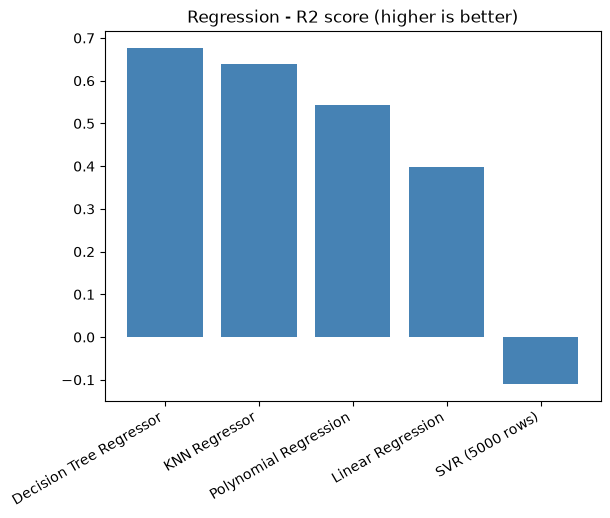

In [47]:
# draw a bar chart of the R2 scores (sorted from best to worst)
sorted_reg = reg_table.sort_values('R2', ascending=False)
plt.bar(sorted_reg['Model'], sorted_reg['R2'], color='steelblue')
plt.title('Regression - R2 score (higher is better)')
plt.xticks(rotation=30, ha='right')
plt.show()

## Step 45: Classification results table

This table collects the accuracy of all four classifiers, sorted from the best to the worst.

In [48]:
# collect the accuracy of every classifier into a table
clf_table = pd.DataFrame({
    'Model': ['Logistic Regression', 'KNN Classifier', 'SVC (5000 rows)', 'Decision Tree Classifier'],
    'Accuracy': [accuracy_score(y_test_c, p) for p in (log_pred, knn_clf_pred, svc_pred, tree_clf_pred)]})
# sort by the best accuracy and show the table
print(clf_table.sort_values('Accuracy', ascending=False).round(4).to_string(index=False))

                   Model  Accuracy
Decision Tree Classifier    0.8933
          KNN Classifier    0.8688
     Logistic Regression    0.8548
         SVC (5000 rows)    0.8086


## Step 46: Classification bar chart

A bar chart makes the accuracy of the four classifiers easy to compare.

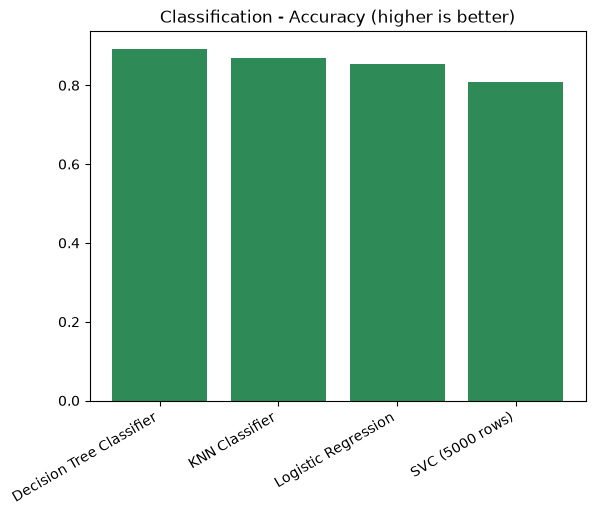

In [49]:
# draw a bar chart of the accuracy scores (sorted from best to worst)
sorted_clf = clf_table.sort_values('Accuracy', ascending=False)
plt.bar(sorted_clf['Model'], sorted_clf['Accuracy'], color='seagreen')
plt.title('Classification - Accuracy (higher is better)')
plt.xticks(rotation=30, ha='right')
plt.show()

## Step 47: Conclusion

- **Regression:** the best model was the **Decision Tree Regressor** (R2 about 0.70), beating Linear Regression, Polynomial Regression and KNN.
- **Classification:** the best model was the **Decision Tree Classifier** (accuracy about 0.89), just above KNN and Logistic Regression.
- SVR did the worst, with a negative R2, so the default SVR settings are not good for this data.
- So the tree models won both jobs, and saying `expensive or not` works well about 9 times out of 10.